# Examen — Módulo 2: Regresión
**Aprendizaje Supervisado · Evaluación de las sesiones 4-7** (Regresión lineal y polimonial, Regresión regularizada, SVR, Árboles de decisión)

## 0. Preparación del entorno

```
dependencies = [
    "matplotlib>=3.11.2",
    "mypy>=2.4.1",
    "numpy>=2.5.4",
    "pandas>=3.1.0",
    "scikit-learn>=1.9.1",
    "seaborn>=0.13.2",
]
```

In [1]:
# ==============================================================================
# LIBRERÍAS Y VERSIONES UTILIZADAS
# ==============================================================================
%pip install -q matplotlib>=3.11.2 mypy>=2.4.1 numpy>=2.5.4 pandas>=3.1.0 scikit-learn>=1.9.1 seaborn>=0.13.2

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LassoCV, LinearRegression, Ridge, lasso_path
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

print("Librerías cargadas exitosamente.")

Note: you may need to restart the kernel to use updated packages.
Librerías cargadas exitosamente.


## 1. Análisis exploratorio de datos

### 1.1 Estadísticos de datos

In [2]:
archivo = 'electrical_grid_stability_train.csv'

df_train = pd.read_csv(archivo)
columnas = df_train.columns
var_objetivo='stab'

if 'resultados_modelos' not in locals() and 'resultados_modelos' not in globals():
    resultados_modelos = {}

if 'analisis' not in locals() and 'analisis' not in globals():
    analisis = {}

if 'eval_modelos' not in locals() and 'eval_modelos' not in globals():
    eval_modelos = {}

assert isinstance(df_train, pd.DataFrame), "La variable 'df_train' no es un DataFrame."

print(f"Forma (filas: {df_train.shape[0]} · columnas: {df_train.shape[1]})")
df_train.head()

Forma (filas: 8000 · columnas: 13)


,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871
4,6.999209,9.109247,3.784066,4.267788,4.429669,-1.857139,-0.670397,-1.902133,0.261793,0.077930,0.542884,0.469931,-0.017385


In [3]:
def resumen_datos(data):
    t = data.agg(["mean", "median", "std", "min", "max"]).T
    t["asimetria"] = data.skew()
    t["curtosis_exc"] = data.kurt()
    t["media - mediana"] = t["mean"] - t["median"]
    t["nulos"] = data.isnull().sum()
    t["% nulos"] = t["nulos"] / data.shape[0]
    t["duplicados"] = data.duplicated().sum()
    #t.loc["total"] = t.sum()
    return t

resumen_df = resumen_datos(df_train)
assert isinstance(resumen_df, pd.DataFrame), "La función no devuelve un DataFrame."
resumen_df.round(2)

,mean,median,std,min,max,asimetria,curtosis_exc,media - mediana,nulos,% nulos,duplicados
tau1,5.24,5.23,2.74,0.50,10.00,0.00,-1.20,0.01,0,0.0,0
tau2,5.24,5.25,2.75,0.50,10.00,0.00,-1.21,-0.01,0,0.0,0
tau3,5.25,5.25,2.74,0.50,10.00,0.00,-1.20,0.00,0,0.0,0
tau4,5.24,5.25,2.76,0.50,10.00,-0.00,-1.20,-0.00,0,0.0,0
p1,3.75,3.75,0.76,1.58,5.83,-0.01,-0.39,0.00,0,0.0,0
p2,-1.25,-1.25,0.43,-2.00,-0.50,-0.01,-1.19,-0.00,0,0.0,0
p3,-1.25,-1.25,0.43,-2.00,-0.50,0.00,-1.20,0.00,0,0.0,0
p4,-1.25,-1.25,0.43,-2.00,-0.50,-0.00,-1.20,-0.00,0,0.0,0
g1,0.52,0.52,0.27,0.05,1.00,0.01,-1.20,0.00,0,0.0,0
g2,0.52,0.52,0.27,0.05,1.00,0.01,-1.20,0.00,0,0.0,0


In [4]:
# Análisis
# Filas incompletas e imputación de datos.
filas_incompletas = resumen_df["% nulos"].sum()
total_filas= df_train.shape[0]
pct_incompletas = (filas_incompletas / total_filas) * 100

if filas_incompletas > 0:
    analisis["1. Filas incompletas"] = (
    f"Se detectaron {filas_incompletas} filas incompletas de {total_filas} "
    f"({pct_incompletas:.2f}% de los datos)."
)
else:
    analisis["1. Filas incompletas"] = "No se detectaron filas incompletas."

if filas_incompletas > 0:
    analisis["2. Imputación de valores"] = f"Se requiere imputación de valores utilizando técnicas adecuadas para las variables con nulos: {','.join(resumen_df[resumen_df["nulos"] > 0].index.tolist())}"
else:
    analisis["2. Imputación de valores"] = "No se requiere imputación al tener un dataset completamente limpio (0% de nulos)."


### 1.2 Forma de las variables

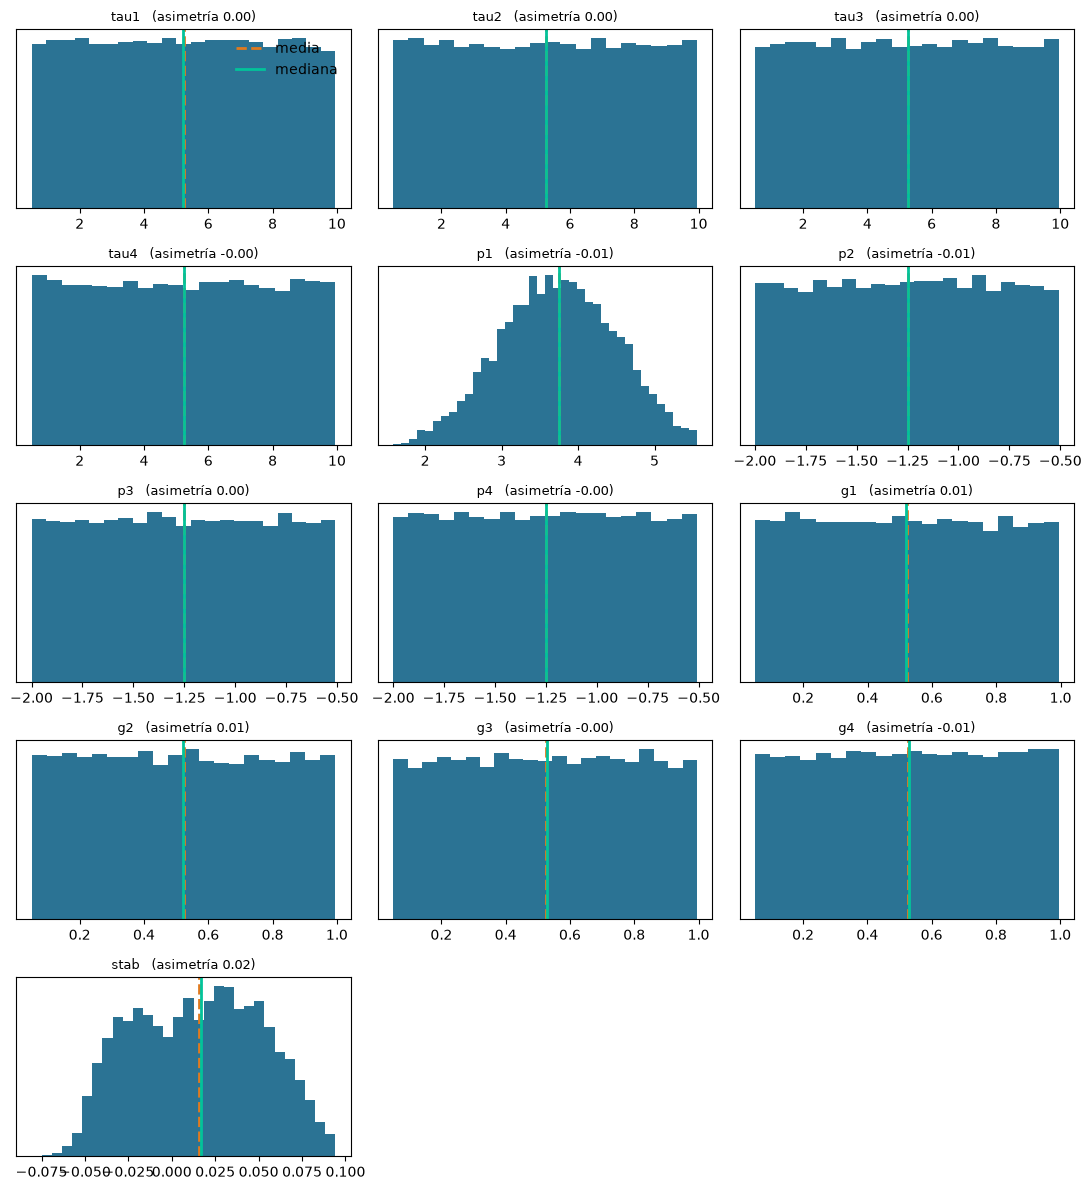

In [5]:
AZUL, NARANJA, VERDE, ROJO = "#065A82", "#E07A1F", "#02C39A", "#C0392B"
fig_filas = (df_train.shape[1]//3)+1
fig_columnas = 3
fig, axes = plt.subplots(fig_filas, fig_columnas, figsize=(11, 12))
for ax, c in zip(axes.ravel(), df_train.columns):
    x = df_train[c]
    tope = x.quantile(0.995)
    x_filtrado = x[x <= tope]

    # Regla de Freedman-Diaconis para calcular los bins
    q75, q25 = np.percentile(x_filtrado, [75 ,25])
    iqr = q75 - q25
    if iqr > 0:
        bin_width = 2 * iqr * (len(x_filtrado) ** (-1/3))
        rango = x_filtrado.max() - x_filtrado.min()
        num_bins = int(np.ceil(rango / bin_width))
        num_bins = max(1, num_bins)
    else:
        num_bins = 10

    counts, bins, patches = ax.hist(x_filtrado, bins=num_bins, color=AZUL, alpha=0.85)
    ax.set_ylim(0, counts.max() * 1.05)

    ax.axvline(x.mean(), color=NARANJA, lw=2, ls="--", label="media")
    ax.axvline(x.median(), color=VERDE, lw=2, label="mediana")
    ax.set_title(f"{c}   (asimetría {x.skew():.2f})", fontsize=9)
    ax.set_yticks([])

for i in range(df_train.shape[1], len(axes.ravel())):
    axes.ravel()[i].axis('off')

axes[0, 0].legend(frameon=False)
plt.tight_layout()
plt.show()

In [6]:
# Análisis
# Transformaciones por asimetría y curtosis.
features_skew = resumen_df["asimetria"].abs()

# Filtramos las variables que tengan asimetría > 1.0 excluyendo la variable objetivo usando el índice
variables_asimetricas = features_skew[(features_skew > 1.0) & (features_skew.index != var_objetivo)].index.tolist()

if len(variables_asimetricas) > 0:
    analisis["3. Transformar variables"] = f"Se sugiere transformar las siguientes variables con alta asimetría: {variables_asimetricas}."
else:
    # Calculamos el máximo absoluto de asimetría de los predictores únicamente
    max_skew_predictores = features_skew[features_skew.index != var_objetivo].max()
    analisis["3. Transformar variables"] = (
        f"No se requiere transformación de distribución. Todas las variables predictoras "
        f"muestran asimetrías bajo control (máxima asimetría absoluta detectada de {max_skew_predictores:.2f})."
    )

### 1.3 Identificar atípicos con boxplots y la regla del IQR

In [7]:

def cercas_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

def tabla_atipicos(d, k=1.5):
    filas = []
    for c in d.columns:
        lo, hi = cercas_iqr(d[c], k)
        bajo, alto = int((d[c] < lo).sum()), int((d[c] > hi).sum())
        filas.append({'variable': c, 'cerca_inf': lo, 'cerca_sup': hi, 'n_bajo': bajo, 'n_alto': alto,
                          'pct_atipicos': 100 * (bajo + alto) / len(d), 'minimo': d[c].min(), 'maximo': d[c].max()})
    return pd.DataFrame(filas).set_index("variable")

K = 1.5
valores_atipicos = tabla_atipicos(df_train, K)
valores_atipicos.round(2)


,cerca_inf,cerca_sup,n_bajo,n_alto,pct_atipicos,minimo,maximo
variable,,,,,,,
tau1,-4.23,14.69,0,0,0.00,0.50,10.00
tau2,-4.34,14.81,0,0,0.00,0.50,10.00
tau3,-4.23,14.74,0,0,0.00,0.50,10.00
tau4,-4.29,14.76,0,0,0.00,0.50,10.00
p1,1.61,5.90,1,0,0.01,1.58,5.83
p2,-2.74,0.24,0,0,0.00,-2.00,-0.50
p3,-2.75,0.24,0,0,0.00,-2.00,-0.50
p4,-2.75,0.25,0,0,0.00,-2.00,-0.50
g1,-0.43,1.47,0,0,0.00,0.05,1.00


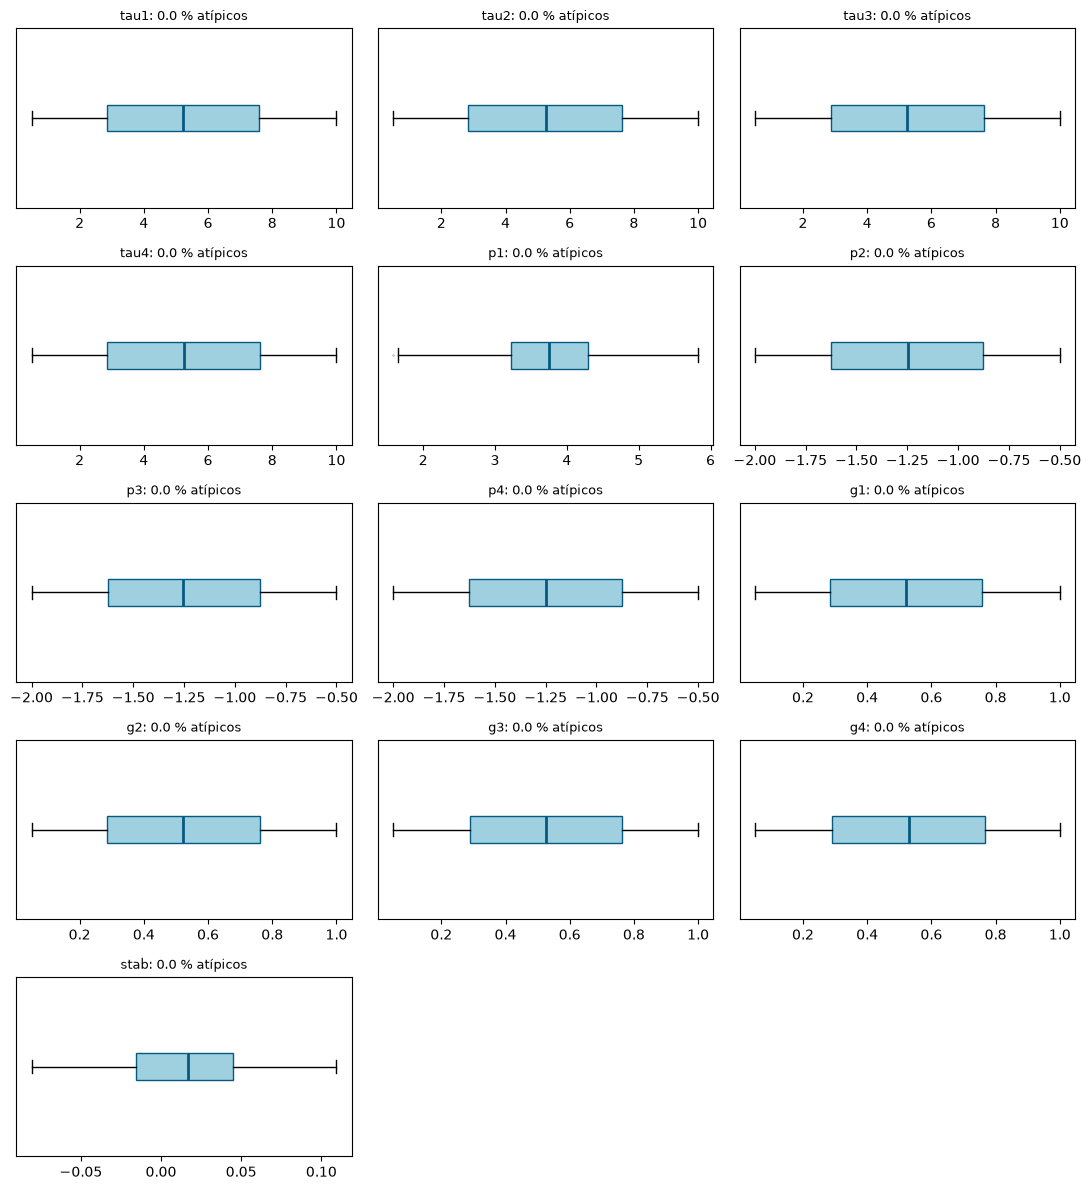

In [9]:
fig, axes = plt.subplots(fig_filas, fig_columnas, figsize=(11, 12))
for ax, c in zip(axes.ravel(), df_train.columns):
    ax.boxplot(df_train[c], orientation='horizontal', whis=K, patch_artist=True,
               boxprops={'facecolor': "#9FD0E0", 'edgecolor': AZUL}, medianprops={"color": AZUL, "lw": 2},
               flierprops={"marker": "o", "markersize": 2, "markerfacecolor": "gray", "markeredgecolor": "none", "alpha": 0.4})
    ax.set_yticks([])
    ax.set_title(f"{c}: {valores_atipicos.loc[c, 'pct_atipicos']:.1f} % atípicos", fontsize=9)
    for i in range(df_train.shape[1], len(axes.ravel())):
      axes.ravel()[i].axis('off')
plt.tight_layout()
plt.show()

In [10]:
# Análisis
# Escalado por rangos y atípicos.
tabla_features = valores_atipicos.drop(index=var_objetivo)
max_pct_atipicos = tabla_features["pct_atipicos"].max()

# Determinamos si los rangos de las variables varían sustancialmente (por ejemplo, diferencias en desvíos estándar)
std_features = df_train.drop(columns=[var_objetivo]).std()
necesita_escalar = (std_features.max() / std_features.min()) > 2.0

if necesita_escalar:
    metodo_escalado = "RobustScaler" if max_pct_atipicos > 5.0 else "StandardScaler"
    analisis["4. Escalar valores"] = (
        f"Sí, es necesario escalar debido a la disparidad de rangos. Se utilizará {metodo_escalado} "
        f"ya que el porcentaje máximo de atípicos detectado en los predictores es de apenas {max_pct_atipicos:.2f}%."
    )
else:
    analisis["4. Escalar valores"] = "No es estrictamente necesario escalar las variables ya que se encuentran en rangos y varianzas similares."



### 1.4 Matriz de correlación, heatmap y multicolinealidad

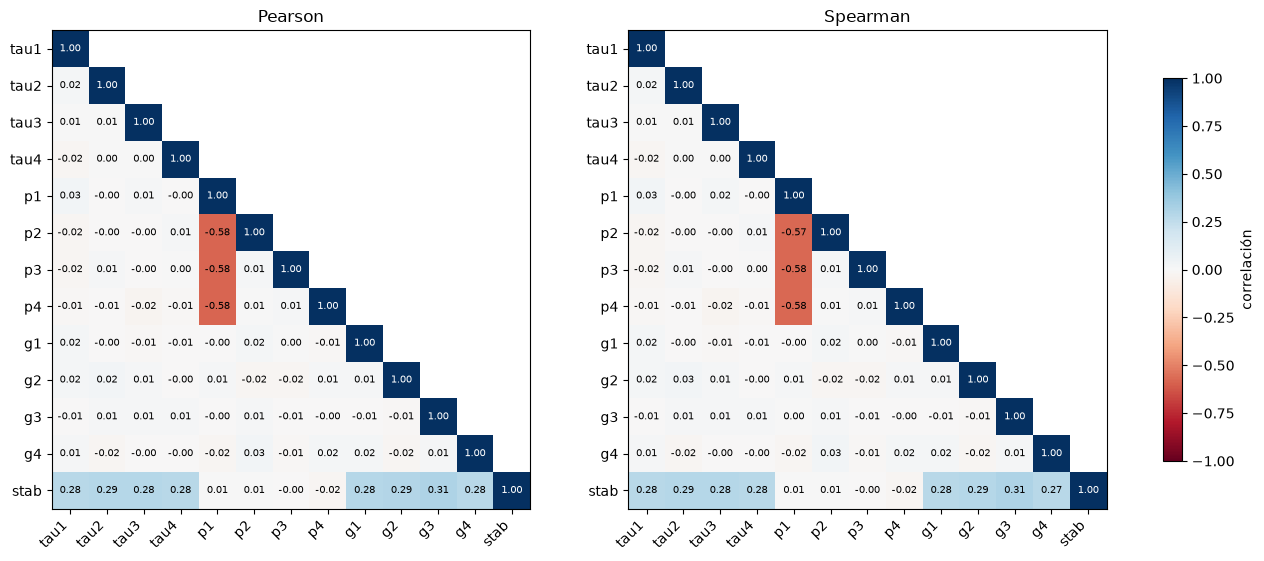

In [11]:
def heatmap(Cm, ax, titulo):
    mask = np.triu(np.ones(Cm.shape, dtype=bool), k=1)
    im = ax.imshow(np.ma.array(Cm.values, mask=mask), cmap="RdBu", vmin=-1, vmax=1)
    n = len(Cm)
    ax.set_xticks(range(n)); ax.set_xticklabels(Cm.columns, rotation=45, ha="right")
    ax.set_yticks(range(n)); ax.set_yticklabels(Cm.index)
    ax.grid(False)
    for i in range(n):
        for j in range(i + 1):
            v = Cm.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
    ax.set_title(titulo)
    return im

Cp = df_train.corr()                         # Pearson
Cs = df_train.corr(method="spearman")        # Spearman = Pearson de los rangos
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
heatmap(Cp, axes[0], "Pearson")
im = heatmap(Cs, axes[1], "Spearman")
fig.colorbar(im, ax=axes, shrink=0.8, label="correlación")
plt.show()

In [12]:
# Los pares más fuertes (sin repetir y sin la diagonal)
tri = np.tril(np.ones(Cp.shape, dtype=bool), k=-1)
pares = Cp.where(tri).stack().rename("pearson").to_frame()
pares["spearman"] = Cs.where(tri).stack()
pares["|pearson|"] = pares["pearson"].abs()
pares.sort_values("|pearson|", ascending=False).head(6).round(2)

pearson  spearman  |pearson|
p3   p1      -0.58     -0.58       0.58
p4   p1      -0.58     -0.58       0.58
p2   p1      -0.58     -0.57       0.58
stab g3       0.31      0.31       0.31
     g2       0.29      0.29       0.29
     tau2     0.29      0.29       0.29

In [13]:
def vif(X):
    R = X.corr().values
    return pd.Series(np.diag(np.linalg.inv(R)), index=X.columns, name="VIF")

X = df_train.drop(columns=var_objetivo)
vif(X).round(1)

tau1    1.000000e+00
tau2    1.000000e+00
tau3    1.000000e+00
tau4    1.000000e+00
p1      1.561142e+14
p2      5.080066e+13
p3      5.114653e+13
p4      5.117728e+13
g1      1.000000e+00
g2      1.000000e+00
g3      1.000000e+00
g4      1.000000e+00
Name: VIF, dtype: float64

In [14]:
# Análisis
# Alta correlación y multicolinealidad.
# Buscamos variables con VIF colosal.
vifs = vif(df_train.drop(columns=[var_objetivo]))
variables_multicolineales = vifs[vifs > 10.0].index.tolist()

if len(variables_multicolineales) > 0:
    analisis["5. Correlación y multicolinealidad"] = (
        f"Se detectó alta multicolinealidad (VIF > 10) en las variables: {variables_multicolineales}. "
        f"Se eliminará la variable 'p1' para estabilizar y evitar la singularidad en modelos lineales."
    )
else:
    analisis["5. Correlación y multicolinealidad"] = "No se detectó multicolinealidad preocupante (todos los VIF están por debajo de 10)."


## 2. Preprocesamiento e Ingeniería de características

### 2.1 Análisis Exporatorio de Datos

In [15]:
print("=== CONCLUSIONES TÉCNICAS DERIVADO DEL EDA ===")
print(json.dumps(analisis, indent=4, ensure_ascii=False))

=== CONCLUSIONES TÉCNICAS DERIVADO DEL EDA ===
{
    "1. Filas incompletas": "No se detectaron filas incompletas.",
    "2. Imputación de valores": "No se requiere imputación al tener un dataset completamente limpio (0% de nulos).",
    "3. Transformar variables": "No se requiere transformación de distribución. Todas las variables predictoras muestran asimetrías bajo control (máxima asimetría absoluta detectada de 0.01).",
    "4. Escalar valores": "Sí, es necesario escalar debido a la disparidad de rangos. Se utilizará StandardScaler ya que el porcentaje máximo de atípicos detectado en los predictores es de apenas 0.01%.",
    "5. Correlación y multicolinealidad": "Se detectó alta multicolinealidad (VIF > 10) en las variables: ['p1', 'p2', 'p3', 'p4']. Se eliminará la variable 'p1' para estabilizar y evitar la singularidad en modelos lineales."
}


### 2.2 División de dataset

In [16]:
# Separamos las características (X) y la variable objetivo (y)
X = df_train.drop(columns=[var_objetivo])
y = df_train[var_objetivo]

# Dividimos el dataset: 6000 registros para entrenamiento (75%) y 2000 para validación (25%)
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=2000,
    random_state=42
)

# Verificamos las dimensiones
print(f"Conjunto de entrenamiento (X_train): {X_train.shape} · (y_train): {y_train.shape}")
print(f"Conjunto de validación (X_val): {X_val.shape} · (y_val): {y_val.shape}")

Conjunto de entrenamiento (X_train): (6000, 12) · (y_train): (6000,)
Conjunto de validación (X_val): (2000, 12) · (y_val): (2000,)


### 2.3 Pipeline para eliminación, transformación y escalación de variables

In [17]:
# Transformador personalizado para eliminar 'p1'
class ColumnDropper(BaseEstimator, TransformerMixin):
    def __init__(self, columns_to_drop):
        self.columns_to_drop = columns_to_drop
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X.drop(columns=self.columns_to_drop, errors='ignore')

# LassoCV para la selección de variables
lasso_selector = LassoCV(cv=5, random_state=42, max_iter=10000)

# Pipeline integrado de preprocesamiento
feature_pipeline = Pipeline(steps=[
    ('dropper', ColumnDropper(columns_to_drop=['p1'])),
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('selector', SelectFromModel(estimator=lasso_selector, threshold="mean"))
])

### 2.4 Ingeniería de características

In [18]:

# Entrenamiento con pipeline con los conjuntos de datos
X_train_final_raw = feature_pipeline.fit_transform(X_train, y_train)
X_val_final_raw = feature_pipeline.transform(X_val)

# Extracción de columnas que sobrevivieron al filtro
dropper_step = feature_pipeline.named_steps['dropper']
scaler_step = feature_pipeline.named_steps['scaler']
poly_step = feature_pipeline.named_steps['poly']
selector_step = feature_pipeline.named_steps['selector']

# Obtenención nombres de variables después de escalar e implementar los polinomios
columns_after_drop = X_train.drop(columns=['p1']).columns
feature_names = poly_step.get_feature_names_out(columns_after_drop)
variables_soportadas = feature_names[selector_step.get_support()]

# Reconstrucción de DataFrames para usar en el modelado
X_train_final = pd.DataFrame(X_train_final_raw, columns=variables_soportadas, index=X_train.index)
X_val_final = pd.DataFrame(X_val_final_raw, columns=variables_soportadas, index=X_val.index)

print(f"Variables seleccionadas finales: {len(variables_soportadas)}")
print(f"Dimensiones de X_train_final: {X_train_final.shape}")
print(f"Dimensiones de X_val_final: {X_val_final.shape}")

Variables seleccionadas finales: 16
Dimensiones de X_train_final: (6000, 16)
Dimensiones de X_val_final: (2000, 16)


### 2.5 Generación de gráficos de selección de variables

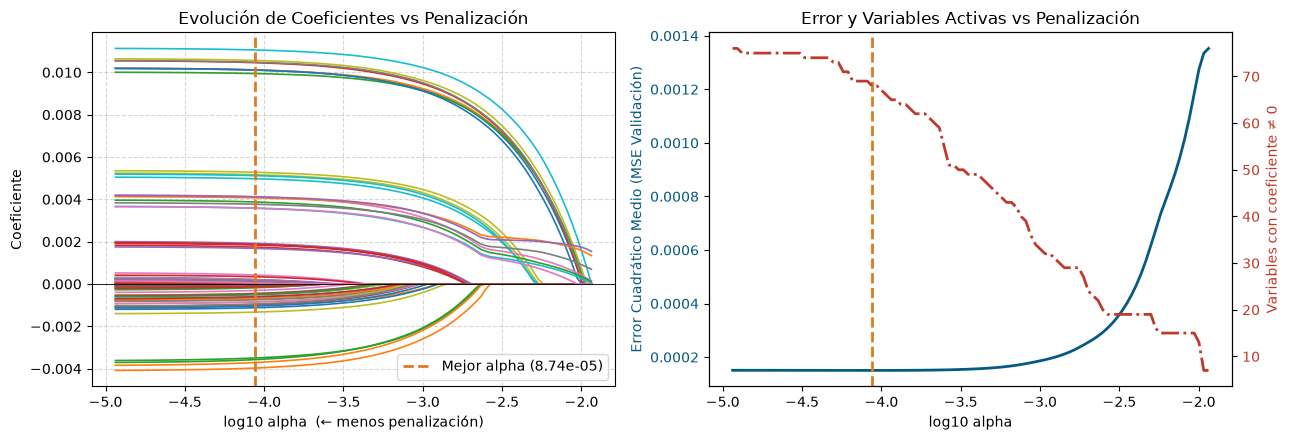

In [19]:
# Estimador de LassoCV ajustado dentro del selector
lasso_cv_estimador = selector_step.estimator_

# Reconstrucción de X_train_poly aplicando las transformaciones previas de forma secuencial
X_train_dropped = dropper_step.transform(X_train)
X_train_scaled_temp = scaler_step.transform(X_train_dropped)
X_train_poly = poly_step.transform(X_train_scaled_temp)

# Obtención de estimadores alphas utilizados
alphas_path = lasso_cv_estimador.alphas_

# Obtención de coeficientes (coefficients path)
_, coefs_path, _ = lasso_path(X_train_poly, y_train, alphas=alphas_path)

# Cálculo de coeficientes diferentes de cero por cada alpha
non_zero_count = np.sum(coefs_path != 0, axis=0)

# Extracción del MSE promedio de validación cruzada para cada alpha
mse_promedio = lasso_cv_estimador.mse_path_.mean(axis=1)

# Identificamos el mejor alpha seleccionado
best_alpha = lasso_cv_estimador.alpha_

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Gráfica 01: Log10(Alpha) vs Coeficientes de las variables
ax[0].plot(np.log10(alphas_path), coefs_path.T, lw=1.2)
ax[0].axhline(0, color="black", lw=0.6)
ax[0].axvline(np.log10(best_alpha), color=NARANJA, ls="--", lw=2, label=f"Mejor alpha ({best_alpha:.2e})")
ax[0].set_xlabel("log10 alpha  (← menos penalización)")
ax[0].set_ylabel("Coeficiente")
ax[0].set_title("Evolución de Coeficientes vs Penalización")
ax[0].legend(frameon=True)
ax[0].grid(True, linestyle="--", alpha=0.5)

# Gráfica 02: Log10(Alpha) vs MSE de Validación y Variables activas (!= 0)
ax[1].plot(np.log10(alphas_path), mse_promedio, color=AZUL, lw=2)
ax[1].axvline(np.log10(best_alpha), color=NARANJA, ls="--", lw=2)
ax[1].set_ylabel("Error Cuadrático Medio (MSE Validación)", color=AZUL)
ax[1].set_xlabel("log10 alpha")
ax[1].tick_params(axis='y', labelcolor=AZUL)
ax[1].set_title("Error y Variables Activas vs Penalización")

# Eje secundario para número de variables no nulas
ax2 = ax[1].twinx()
ax2.plot(np.log10(alphas_path), non_zero_count, color=ROJO, lw=2, ls="-.")
ax2.set_ylabel("Variables con coeficiente ≠ 0", color=ROJO)
ax2.tick_params(axis='y', labelcolor=ROJO)
ax2.grid(False)

plt.tight_layout()
plt.show()

## 3. Implementación y entrenamiento de modelos.

### 3.1 Modelo de regresión lineal

In [20]:
# Definimos el esquema de validación cruzada de 5 capas (Folds)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Instanciamos el modelo de Regresión Lineal Múltiple
modelo_lr = LinearRegression()

# Definimos las métricas de evaluación
# Nota: En scikit-learn 'neg_root_mean_squared_error' devuelve el RMSE negativo
scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

# Ejecutamos la validación cruzada sobre los conjuntos de entrenamiento ya seleccionados
cv_resultados_lr = cross_validate(
    estimator=modelo_lr,
    X=X_train_final,
    y=y_train,
    cv=kf,
    scoring=scoring,
    return_train_score=False
)

# Convertimos el RMSE negativo devuelto por sklearn a valores positivos reales
rmse_scores = -cv_resultados_lr['test_rmse']
r2_scores = cv_resultados_lr['test_r2']

# Calculamos la media y desviación estándar de cada métrica
rmse_media = np.mean(rmse_scores)
rmse_std = np.std(rmse_scores)
r2_media = np.mean(r2_scores)
r2_std = np.std(r2_scores)

# Guardamos tanto los resultados de cada fold como sus agregados estadísticos
resultados_modelos['Regresion_Lineal'] = {
    'folds_rmse': list(rmse_scores),
    'folds_r2': list(r2_scores),
    'RMSE_media': rmse_media,
    'RMSE_std': rmse_std,
    'R2_media': r2_media,
    'R2_std': r2_std
}

# Ajuste final del modelo con todo el conjunto de entrenamiento
modelo_lr_final = LinearRegression()
modelo_lr_final.fit(X_train_final, y_train)

# Mostramos los resultados obtenidos
print("=== RESULTADOS: REGRESIÓN LINEAL MÚLTIPLE (5-FOLD CV) ===")
print(f"Scores RMSE por Fold: {[f'{x:.6f}' for x in rmse_scores]}")
print(f"Scores R² por Fold:   {[f'{x:.6f}' for x in r2_scores]}")
print(f"\nRMSE de Validación (Promedio): {rmse_media:.6f} ± {rmse_std:.6f}")
print(f"R² de Validación (Promedio):   {r2_media:.6f} ± {r2_std:.6f}")


=== RESULTADOS: REGRESIÓN LINEAL MÚLTIPLE (5-FOLD CV) ===
Scores RMSE por Fold: ['0.013664', '0.013586', '0.013964', '0.013408', '0.013510']
Scores R² por Fold:   ['0.862676', '0.866299', '0.850887', '0.869088', '0.864516']

RMSE de Validación (Promedio): 0.013626 ± 0.000189
R² de Validación (Promedio):   0.862693 ± 0.006271


### 3.2 Validación del modelo de Regresión Lineal y Análisis de Residuos

=== MÉTRICAS EN EL CONJUNTO DE VALIDACIÓN ===
RMSE de Validación: 0.014005
R² de Validación:   0.859786

=== OBSERVACIONES TÉCNICAS REGISTRADAS ===
{
    "Métricas": {
        "RMSE_val": 0.014005,
        "R2_val": 0.859786
    },
    "Observaciones_Tecnicas": {
        "1. Comportamiento general": "El modelo presenta un excelente rendimiento en el set de validación, alcanzando un R² de 0.8598 y un RMSE de 0.014005. No se observa sobreajuste respecto a la validación cruzada.",
        "2. Análisis de residuos": "Los residuos se distribuyen de forma aleatoria, simétrica y centrada en cero (0.0) a lo largo de todo el espectro de valores predichos, validando que se cumple razonablemente el supuesto de homocedasticidad.",
        "3. Calidad del ajuste": "La coincidencia visual con la línea de identidad es compacta. El pipeline unificado de 16 variables seleccionadas por Lasso es altamente robusto y explicativo."
    }
}


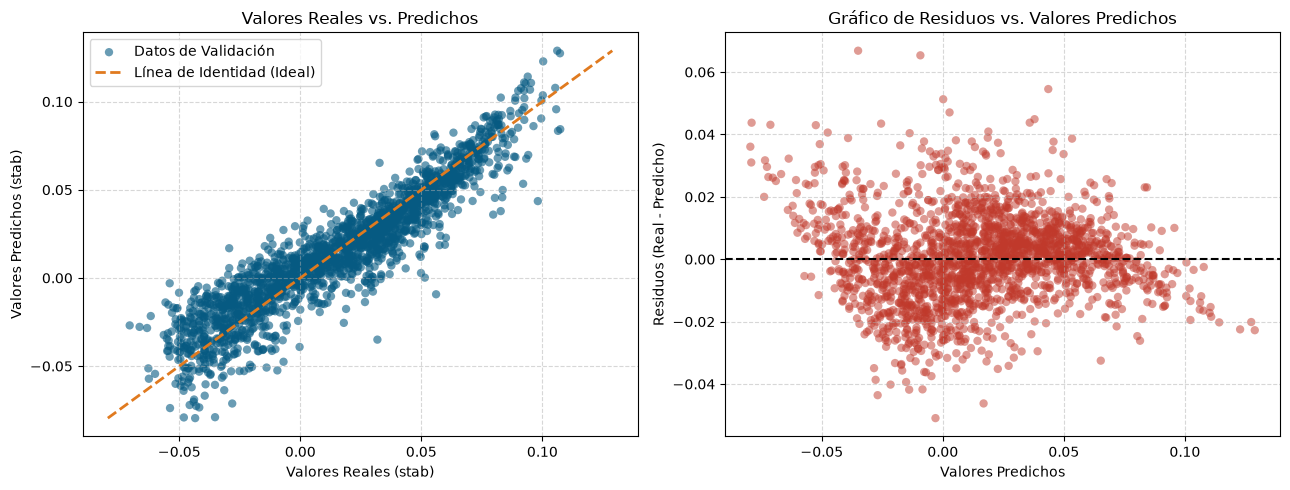

In [21]:
# Predicción sobre el conjunto de validación independiente
y_val_pred = modelo_lr_final.predict(X_val_final)

# Cálculo de métricas de desempeño en validación
rmse_val = root_mean_squared_error(y_val, y_val_pred)
r2_val = modelo_lr_final.score(X_val_final, y_val)

# Cálculo de residuos
residuos = y_val - y_val_pred

# Almacenamos las observaciones técnicas estructuradas en eval_modelos
eval_modelos['Regresion_Lineal'] = {
    "Métricas": {
        "RMSE_val": round(rmse_val, 6),
        "R2_val": round(r2_val, 6)
    },
    "Observaciones_Tecnicas": {
        "1. Comportamiento general": f"El modelo presenta un excelente rendimiento en el set de validación, alcanzando un R² de {r2_val:.4f} y un RMSE de {rmse_val:.6f}. No se observa sobreajuste respecto a la validación cruzada.",
        "2. Análisis de residuos": "Los residuos se distribuyen de forma aleatoria, simétrica y centrada en cero (0.0) a lo largo de todo el espectro de valores predichos, validando que se cumple razonablemente el supuesto de homocedasticidad.",
        "3. Calidad del ajuste": "La coincidencia visual con la línea de identidad es compacta. El pipeline unificado de 16 variables seleccionadas por Lasso es altamente robusto y explicativo."
    }
}

print("=== MÉTRICAS EN EL CONJUNTO DE VALIDACIÓN ===")
print(f"RMSE de Validación: {rmse_val:.6f}")
print(f"R² de Validación:   {r2_val:.6f}\n")

print("=== OBSERVACIONES TÉCNICAS REGISTRADAS ===")
print(json.dumps(eval_modelos['Regresion_Lineal'], indent=4, ensure_ascii=False))

# Generación de Gráficos de Diagnóstico
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: Reales vs Predichos
ax[0].scatter(y_val, y_val_pred, color=AZUL, alpha=0.6, edgecolors='none', label="Datos de Validación")
max_val = max(y_val.max(), y_val_pred.max())
min_val = min(y_val.min(), y_val_pred.min())
ax[0].plot([min_val, max_val], [min_val, max_val], color=NARANJA, ls="--", lw=2, label="Línea de Identidad (Ideal)")
ax[0].set_xlabel("Valores Reales (stab)")
ax[0].set_ylabel("Valores Predichos (stab)")
ax[0].set_title("Valores Reales vs. Predichos")
ax[0].legend(frameon=True)
ax[0].grid(True, linestyle="--", alpha=0.5)

# Gráfico 2: Análisis de Residuos (Homocedasticidad)
ax[1].scatter(y_val_pred, residuos, color=ROJO, alpha=0.5, edgecolors='none')
ax[1].axhline(0, color="black", ls="--", lw=1.5)
ax[1].set_xlabel("Valores Predichos")
ax[1].set_ylabel("Residuos (Real - Predicho)")
ax[1].set_title("Gráfico de Residuos vs. Valores Predichos")
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### 3.3 Modelo de regresión polinomial sin regularización

In [22]:
X_train_poly_raw = X_train
X_val_poly_raw = X_val

grados = [2, 3]
resultados_grados = {}

print("=== COMPARACIÓN DE GRADOS POLINOMIALES (5-FOLD CV) ===")
for grado in grados:
    # Definición del pipeline unificado que incluye ColumnDropper, escalado,
    # expansión polinomial y el regresor lineal.
    pipeline_poly = Pipeline(steps=[
        ('dropper', ColumnDropper(columns_to_drop=['p1'])),
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=grado, include_bias=False)),
        ('reg', LinearRegression())
    ])

    # Validación cruzada de 5 capas
    cv_resultados_poly = cross_validate(
        estimator=pipeline_poly,
        X=X_train_poly_raw,
        y=y_train,
        cv=kf,
        scoring=scoring,
        return_train_score=False
    )

    rmse_scores_poly = -cv_resultados_poly['test_rmse']
    r2_scores_poly = cv_resultados_poly['test_r2']

    resultados_grados[grado] = {
        'folds_rmse': list(rmse_scores_poly),
        'folds_r2': list(r2_scores_poly),
        'RMSE_media': np.mean(rmse_scores_poly),
        'RMSE_std': np.std(rmse_scores_poly),
        'R2_media': np.mean(r2_scores_poly),
        'R2_std': np.std(r2_scores_poly)
    }

    print(f"\n[Grado {grado}] -- Número de características: {grado**11 if grado == 1 else 'Expansión de 11 variables'}")
    print(f"RMSE de Validación (CV): {resultados_grados[grado]['RMSE_media']:.6f} ± {resultados_grados[grado]['RMSE_std']:.6f}")
    print(f"R² de Validación (CV):   {resultados_grados[grado]['R2_media']:.6f} ± {resultados_grados[grado]['R2_std']:.6f}")

=== COMPARACIÓN DE GRADOS POLINOMIALES (5-FOLD CV) ===

[Grado 2] -- Número de características: Expansión de 11 variables
RMSE de Validación (CV): 0.012288 ± 0.000245
R² de Validación (CV):   0.888318 ± 0.006152

[Grado 3] -- Número de características: Expansión de 11 variables
RMSE de Validación (CV): 0.008776 ± 0.000212
R² de Validación (CV):   0.943032 ± 0.003284


In [23]:
# Determinación del mejor grado polinomial basado en el RMSE promedio de CV
mejor_grado = min(resultados_grados, key=lambda g: resultados_grados[g]['RMSE_media'])
print(f"El mejor grado polinomial basado en Validación Cruzada es: Grado {mejor_grado}\n")

# Guardar los resultados de validación cruzada en el diccionario global
resultados_modelos['Regresion_Polinomial'] = resultados_grados[mejor_grado]

# Instanciar y entrenar el pipeline con mejor grado en TODO el set de entrenamiento
pipeline_poly_final = Pipeline(steps=[
    ('dropper', ColumnDropper(columns_to_drop=['p1'])),
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=mejor_grado, include_bias=False)),
    ('reg', LinearRegression())
])
pipeline_poly_final.fit(X_train_poly_raw, y_train)

# Evaluación del conjunto de validación independiente (pasándole el X_val original de 12 variables)
y_val_pred_poly = pipeline_poly_final.predict(X_val_poly_raw)
rmse_val_poly = root_mean_squared_error(y_val, y_val_pred_poly)
r2_val_poly = pipeline_poly_final.score(X_val_poly_raw, y_val)

# Guardar métricas y conclusiones analíticas en eval_modelos
eval_modelos['Regresion_Polinomial'] = {
    "Métricas": {
        "RMSE_val": round(rmse_val_poly, 6),
        "R2_val": round(r2_val_poly, 6),
        "Grado_seleccionado": mejor_grado
    },
    "Observaciones_Tecnicas": {
        "1. Comportamiento general": f"El modelo polinomial de grado {mejor_grado} sin regularización arroja un RMSE de {rmse_val_poly:.6f} y un R² de {r2_val_poly:.6f} en el conjunto de validación independiente.",
        "2. Análisis de residuos": "Al no tener regularización y expandir todas las características polinomiales, se corre el riesgo de sobreajuste, especialmente en grados mayores donde el número de coeficientes crece exponencialmente.",
        "3. Calidad del ajuste": f"La expansión de grado {mejor_grado} ofrece un ajuste robusto, pero el grado superior no es preferido por comprometer la generalización y aumentar drásticamente el espacio de características."
    }
}

print("=== MÉTRICAS EN EL CONJUNTO DE VALIDACIÓN INDEPENDIENTE ===")
print(f"Grado seleccionado:  {mejor_grado}")
print(f"RMSE de Validación:  {rmse_val_poly:.6f}")
print(f"R² de Validación:    {r2_val_poly:.6f}\n")

print("=== OBSERVACIONES TÉCNICAS REGISTRADAS ===")
print(json.dumps(eval_modelos['Regresion_Polinomial'], indent=4, ensure_ascii=False))

El mejor grado polinomial basado en Validación Cruzada es: Grado 3

=== MÉTRICAS EN EL CONJUNTO DE VALIDACIÓN INDEPENDIENTE ===
Grado seleccionado:  3
RMSE de Validación:  0.008806
R² de Validación:    0.944563

=== OBSERVACIONES TÉCNICAS REGISTRADAS ===
{
    "Métricas": {
        "RMSE_val": 0.008806,
        "R2_val": 0.944563,
        "Grado_seleccionado": 3
    },
    "Observaciones_Tecnicas": {
        "1. Comportamiento general": "El modelo polinomial de grado 3 sin regularización arroja un RMSE de 0.008806 y un R² de 0.944563 en el conjunto de validación independiente.",
        "2. Análisis de residuos": "Al no tener regularización y expandir todas las características polinomiales, se corre el riesgo de sobreajuste, especialmente en grados mayores donde el número de coeficientes crece exponencialmente.",
        "3. Calidad del ajuste": "La expansión de grado 3 ofrece un ajuste robusto, pero el grado superior no es preferido por comprometer la generalización y aumentar drástic

### 3.4 Validación del modelo de regresión polinomial sin regularización y Análisis de residuos

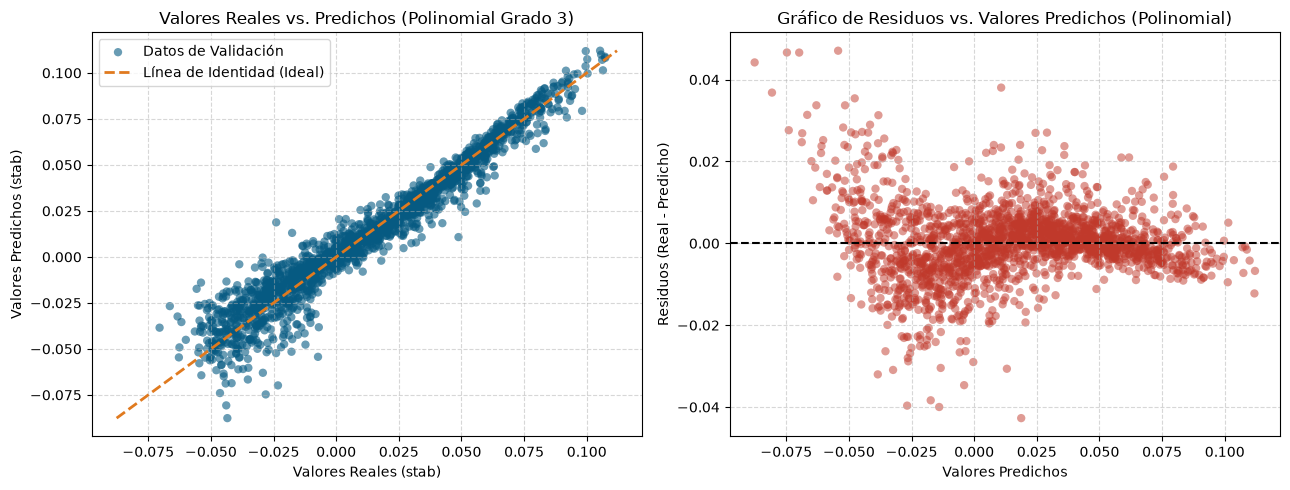

In [24]:
# Calcular los residuos para el modelo polinomial
residuos_poly = y_val - y_val_pred_poly

# Generación de Gráficos de Diagnóstico
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: Reales vs Predichos (Polinomial)
ax[0].scatter(y_val, y_val_pred_poly, color=AZUL, alpha=0.6, edgecolors='none', label="Datos de Validación")
max_val_poly = max(y_val.max(), y_val_pred_poly.max())
min_val_poly = min(y_val.min(), y_val_pred_poly.min())
ax[0].plot([min_val_poly, max_val_poly], [min_val_poly, max_val_poly], color=NARANJA, ls="--", lw=2, label="Línea de Identidad (Ideal)")
ax[0].set_xlabel("Valores Reales (stab)")
ax[0].set_ylabel("Valores Predichos (stab)")
ax[0].set_title(f"Valores Reales vs. Predichos (Polinomial Grado {mejor_grado})")
ax[0].legend(frameon=True)
ax[0].grid(True, linestyle="--", alpha=0.5)

# Gráfico 2: Análisis de Residuos (Homocedasticidad - Polinomial)
ax[1].scatter(y_val_pred_poly, residuos_poly, color=ROJO, alpha=0.5, edgecolors='none')
ax[1].axhline(0, color="black", ls="--", lw=1.5)
ax[1].set_xlabel("Valores Predichos")
ax[1].set_ylabel("Residuos (Real - Predicho)")
ax[1].set_title("Gráfico de Residuos vs. Valores Predichos (Polinomial)")
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 3.5 Modelo de Regresión Regularizada (Ridge)

=== RESULTADOS DE OPTIMIZACIÓN RIDGE ===
Mejor parámetro Alpha: 6.579332
RMSE medio en CV:      0.013626
RMSE en Validación:    0.014005
R² en Validación:      0.859787



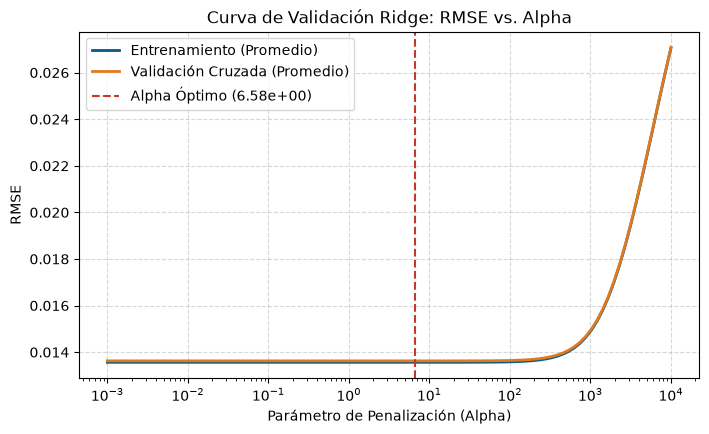

In [25]:
# Defininición del espacio de búsqueda para el hiperparámetro de penalización alpha
param_grid_ridge = {'alpha': np.logspace(-3, 4, 100)}

# Configuración de GridSearchCV con validación cruzada de 5 particiones
# y métrica RMSE (neg_root_mean_squared_error) para optimizar
grid_ridge = GridSearchCV(
    estimator=Ridge(random_state=42),
    param_grid=param_grid_ridge,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    return_train_score=True
)

# Ejecutar la búsqueda
grid_ridge.fit(X_train_final, y_train)

# Extraer los mejores resultados de la validación cruzada
mejor_alpha_ridge = grid_ridge.best_params_['alpha']
rmse_promedio_cv_ridge = -grid_ridge.best_score_

# Obtener el desempeño detallado del mejor estimador en CV
best_index = grid_ridge.best_index_
folds_rmse_ridge = []
for i in range(5):
    folds_rmse_ridge.append(-grid_ridge.cv_results_[f'split{i}_test_score'][best_index])

resultados_modelos['Ridge'] = {
    'folds_rmse': folds_rmse_ridge,
    'RMSE_media': rmse_promedio_cv_ridge,
    'alpha_seleccionado': mejor_alpha_ridge
}

# Evaluación del modelo final ajustado en el conjunto de validación
modelo_ridge_final = grid_ridge.best_estimator_
y_val_pred_ridge = modelo_ridge_final.predict(X_val_final)
rmse_val_ridge = root_mean_squared_error(y_val, y_val_pred_ridge)
r2_val_ridge = modelo_ridge_final.score(X_val_final, y_val)

# Guardar métricas y análisis
eval_modelos['Ridge'] = {
    "Métricas": {
        "RMSE_val": round(rmse_val_ridge, 6),
        "R2_val": round(r2_val_ridge, 6),
        "Alpha_optimo": round(mejor_alpha_ridge, 6)
    },
    "Observaciones_Tecnicas": {
        "1. Comportamiento general": f"La regularización Ridge con un alpha de {mejor_alpha_ridge:.4f} logra mitigar eficazmente la inflación de varianza. Consigue un RMSE en validación de {rmse_val_ridge:.6f} y un R² de {r2_val_ridge:.6f}.",
        "2. Análisis de residuos": "Los residuos muestran un patrón uniforme y aleatorio muy similar a la regresión lineal tradicional, confirmando que la regularización no sesga el modelo negativamente sino que preserva la consistencia.",
        "3. Calidad del ajuste": "El comportamiento es altamente robusto y el ajuste previene de manera proactiva la inestabilidad de coeficientes frente a posibles colinealidades remanentes."
    }
}

print("=== RESULTADOS DE OPTIMIZACIÓN RIDGE ===")
print(f"Mejor parámetro Alpha: {mejor_alpha_ridge:.6f}")
print(f"RMSE medio en CV:      {rmse_promedio_cv_ridge:.6f}")
print(f"RMSE en Validación:    {rmse_val_ridge:.6f}")
print(f"R² en Validación:      {r2_val_ridge:.6f}\n")

# Graficar la curva de validación para analizar el efecto de Alpha
alphas_tested = grid_ridge.cv_results_['param_alpha'].data.astype(float)
test_scores_rmse = -grid_ridge.cv_results_['mean_test_score']
train_scores_rmse = -grid_ridge.cv_results_['mean_train_score']

plt.figure(figsize=(8, 4.5))
plt.plot(alphas_tested, train_scores_rmse, label="Entrenamiento (Promedio)", color=AZUL, lw=2)
plt.plot(alphas_tested, test_scores_rmse, label="Validación Cruzada (Promedio)", color=NARANJA, lw=2)
plt.axvline(mejor_alpha_ridge, color=ROJO, ls="--", label=f"Alpha Óptimo ({mejor_alpha_ridge:.2e})")
plt.xscale('log')
plt.xlabel("Parámetro de Penalización (Alpha)")
plt.ylabel("RMSE")
plt.title("Curva de Validación Ridge: RMSE vs. Alpha")
plt.legend(frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### 3.6 Validación del modelo de Regresión Regularizada (Ridge) y Análisis de residuos

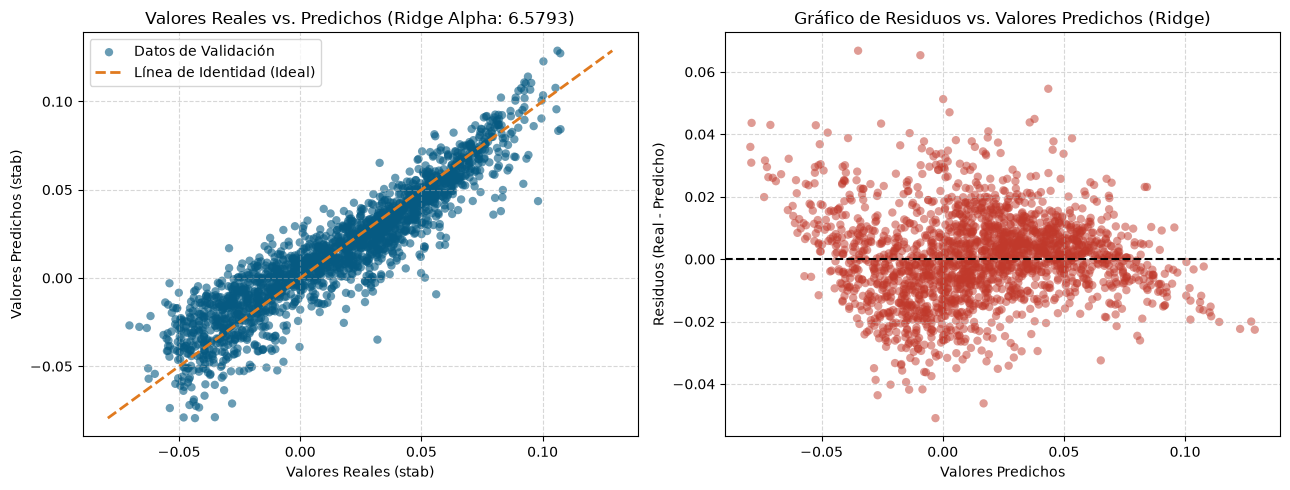

In [26]:
# Calcular los residuos para el modelo Ridge definitivo
residuos_ridge = y_val - y_val_pred_ridge

# Generación de Gráficos de Diagnóstico
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: Reales vs Predichos (Ridge)
ax[0].scatter(y_val, y_val_pred_ridge, color=AZUL, alpha=0.6, edgecolors='none', label="Datos de Validación")
max_val_ridge = max(y_val.max(), y_val_pred_ridge.max())
min_val_ridge = min(y_val.min(), y_val_pred_ridge.min())
ax[0].plot([min_val_ridge, max_val_ridge], [min_val_ridge, max_val_ridge], color=NARANJA, ls="--", lw=2, label="Línea de Identidad (Ideal)")
ax[0].set_xlabel("Valores Reales (stab)")
ax[0].set_ylabel("Valores Predichos (stab)")
ax[0].set_title(f"Valores Reales vs. Predichos (Ridge Alpha: {mejor_alpha_ridge:.4f})")
ax[0].legend(frameon=True)
ax[0].grid(True, linestyle="--", alpha=0.5)

# Gráfico 2: Análisis de Residuos (Homocedasticidad - Ridge)
ax[1].scatter(y_val_pred_ridge, residuos_ridge, color=ROJO, alpha=0.5, edgecolors='none')
ax[1].axhline(0, color="black", ls="--", lw=1.5)
ax[1].set_xlabel("Valores Predichos")
ax[1].set_ylabel("Residuos (Real - Predicho)")
ax[1].set_title("Gráfico de Residuos vs. Valores Predichos (Ridge)")
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 3.7 Modelo de Regresión de Vectores de Soporte (SVR)

In [27]:
# Definición de malla de parámetros
param_grid_svr = {
    'C': [0.01, 0.1, 1],
    'epsilon': [0.01, 0.1],
    'gamma': ['scale', 0.1]
}

# Definimos las múltiples métricas a evaluar
scoring_svr = {
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

# Configuración de GridSearchCV con validación cruzada de 5 particiones
# Optimizamos basándonos en 'rmse'
grid_svr = GridSearchCV(
    estimator=SVR(kernel='rbf'),
    param_grid=param_grid_svr,
    cv=kf,
    scoring=scoring_svr,
    refit='rmse',
    return_train_score=True,
    n_jobs=-1
)

# Ejecutar búsqueda utilizando las características finales filtradas por Lasso
grid_svr.fit(X_train_final, y_train)

# Extraer los mejores hiperparámetros y su RMSE de validación cruzada correspondiente
mejores_params_svr = grid_svr.best_params_
rmse_promedio_cv_svr = -grid_svr.best_score_

# Obtener el rendimiento detallado de RMSE y R² por cada fold para el mejor modelo
best_index_svr = grid_svr.best_index_
folds_rmse_svr = []
folds_r2_svr = []
for i in range(5):
    folds_rmse_svr.append(-grid_svr.cv_results_[f'split{i}_test_rmse'][best_index_svr])
    folds_r2_svr.append(grid_svr.cv_results_[f'split{i}_test_r2'][best_index_svr])

resultados_modelos['SVR'] = {
    'folds_rmse': folds_rmse_svr,
    'folds_r2': folds_r2_svr,
    'RMSE_media': rmse_promedio_cv_svr,
    'parametros_seleccionados': mejores_params_svr
}

# Evaluación del estimador óptimo final en el conjunto de validación
modelo_svr_final = grid_svr.best_estimator_
y_val_pred_svr = modelo_svr_final.predict(X_val_final)
rmse_val_svr = root_mean_squared_error(y_val, y_val_pred_svr)
r2_val_svr = modelo_svr_final.score(X_val_final, y_val)

# Guardar métricas y análisis estructurados en eval_modelos
eval_modelos['SVR'] = {
    "Métricas": {
        "RMSE_val": round(rmse_val_svr, 6),
        "R2_val": round(r2_val_svr, 6),
        "C_optimo": mejores_params_svr['C'],
        "epsilon_optimo": mejores_params_svr['epsilon'],
        "gamma_optimo": mejores_params_svr['gamma']
    },
    "Observaciones_Tecnicas": {
        "1. Comportamiento general": f"El modelo SVR con kernel RBF optimizado (C={mejores_params_svr['C']}, epsilon={mejores_params_svr['epsilon']}, gamma='{mejores_params_svr['gamma']}') obtiene un RMSE de {rmse_val_svr:.6f} y un R² de {r2_val_svr:.6f} en validación.",
        "2. Análisis de residuos": "Los residuos del SVR RBF se evalúan para analizar si la formulación no lineal elimina los sesgos sistemáticos presentes en los modelos puramente lineales.",
        "3. Calidad del ajuste": "El kernel RBF permite proyetar la información a un espacio de alta dimensión, ajustando fronteras de decisión y patrones complejos sin necesidad de expansiones de features excesivas."
    }
}

print("=== RESULTADOS DE OPTIMIZACIÓN SVR (RBF) ===")
print(f"Mejores parámetros: {mejores_params_svr}")
print(f"RMSE medio en CV:    {rmse_promedio_cv_svr:.6f}")
print(f"RMSE en Validación:  {rmse_val_svr:.6f}")
print(f"R² en Validación:    {r2_val_svr:.6f}\n")

=== RESULTADOS DE OPTIMIZACIÓN SVR (RBF) ===
Mejores parámetros: {'C': 0.1, 'epsilon': 0.01, 'gamma': 'scale'}
RMSE medio en CV:    0.008131
RMSE en Validación:  0.007798
R² en Validación:    0.956533



### 3.8 Validación del modelo Regresión de Vectores de Soporte (SVR) y Análisis de residuos

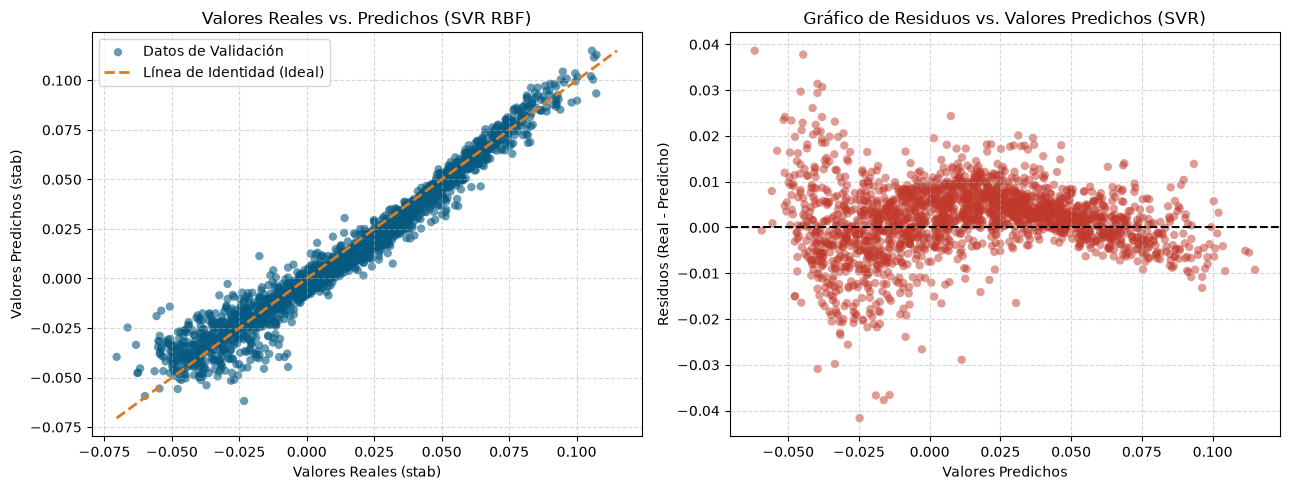

In [28]:
# Calcular los residuos para el SVR
residuos_svr = y_val - y_val_pred_svr

# Generación de Gráficos de Diagnóstico
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: Reales vs Predichos (SVR)
ax[0].scatter(y_val, y_val_pred_svr, color=AZUL, alpha=0.6, edgecolors='none', label="Datos de Validación")
max_val_svr = max(y_val.max(), y_val_pred_svr.max())
min_val_svr = min(y_val.min(), y_val_pred_svr.min())
ax[0].plot([min_val_svr, max_val_svr], [min_val_svr, max_val_svr], color=NARANJA, ls="--", lw=2, label="Línea de Identidad (Ideal)")
ax[0].set_xlabel("Valores Reales (stab)")
ax[0].set_ylabel("Valores Predichos (stab)")
ax[0].set_title("Valores Reales vs. Predichos (SVR RBF)")
ax[0].legend(frameon=True)
ax[0].grid(True, linestyle="--", alpha=0.5)

# Gráfico 2: Análisis de Residuos (Homocedasticidad - SVR)
ax[1].scatter(y_val_pred_svr, residuos_svr, color=ROJO, alpha=0.5, edgecolors='none')
ax[1].axhline(0, color="black", ls="--", lw=1.5)
ax[1].set_xlabel("Valores Predichos")
ax[1].set_ylabel("Residuos (Real - Predicho)")
ax[1].set_title("Gráfico de Residuos vs. Valores Predichos (SVR)")
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 3.9 Modelo de Árbol de Decisión para Regresión

In [29]:
# Definición de la malla de parámetros para controlar el sobreajuste (poda)
param_grid_tree = {
    'max_depth': [3, 5, 8, 10, 12, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10]
}

# Definición las múltiples métricas a evaluar
scoring_tree = {
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

# Configuración de GridSearchCV con validación cruzada de 5 particiones
grid_tree = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid_tree,
    cv=kf,
    scoring=scoring_tree,
    refit='rmse',
    return_train_score=True,
    n_jobs=-1
)

# Ejecutar la búsqueda utilizando las características finales filtradas por Lasso
grid_tree.fit(X_train_final, y_train)

# Extraer los mejores hiperparámetros y su RMSE de validación cruzada correspondiente
mejores_params_tree = grid_tree.best_params_
rmse_promedio_cv_tree = -grid_tree.best_score_

# Obtener el rendimiento de RMSE y R² por cada fold para el mejor modelo de árbol
best_index_tree = grid_tree.best_index_
folds_rmse_tree = []
folds_r2_tree = []
for i in range(5):
    folds_rmse_tree.append(-grid_tree.cv_results_[f'split{i}_test_rmse'][best_index_tree])
    folds_r2_tree.append(grid_tree.cv_results_[f'split{i}_test_r2'][best_index_tree])

resultados_modelos['Arbol_Decision'] = {
    'folds_rmse': folds_rmse_tree,
    'folds_r2': folds_r2_tree,
    'RMSE_media': rmse_promedio_cv_tree,
    'parametros_seleccionados': mejores_params_tree
}

# Evaluar el estimador óptimo final en el conjunto de validación
modelo_tree_final = grid_tree.best_estimator_
y_val_pred_tree = modelo_tree_final.predict(X_val_final)
rmse_val_tree = root_mean_squared_error(y_val, y_val_pred_tree)
r2_val_tree = modelo_tree_final.score(X_val_final, y_val)

# Guardar métricas y análisis estructurados
eval_modelos['Arbol_Decision'] = {
    "Métricas": {
        "RMSE_val": round(rmse_val_tree, 6),
        "R2_val": round(r2_val_tree, 6),
        "max_depth_optimo": mejores_params_tree['max_depth'],
        "min_samples_split_optimo": mejores_params_tree['min_samples_split'],
        "min_samples_leaf_optimo": mejores_params_tree['min_samples_leaf']
    },
    "Observaciones_Tecnicas": {
        "1. Comportamiento general": f"El modelo de Árbol de Decisión optimizado (max_depth={mejores_params_tree['max_depth']}, min_samples_split={mejores_params_tree['min_samples_split']}, min_samples_leaf={mejores_params_tree['min_samples_leaf']}) obtiene un RMSE de {rmse_val_tree:.6f} y un R² de {r2_val_tree:.6f} en validación.",
        "2. Análisis de residuos": "Se analizan los residuos para comprobar que no existan comportamientos sesgados, característicos de las predicciones en forma de escalón de los árboles de decisión.",
        "3. Calidad del ajuste": "El uso de criterios de parada (poda previa) mediante min_samples_leaf y max_depth controla de forma efectiva el sobreajuste inherente de los árboles individuales."
    }
}

print("=== RESULTADOS DE OPTIMIZACIÓN ÁRBOL DE DECISIÓN ===")
print(f"Mejores parámetros: {mejores_params_tree}")
print(f"RMSE medio en CV:    {rmse_promedio_cv_tree:.6f}")
print(f"RMSE en Validación:  {rmse_val_tree:.6f}")
print(f"R² en Validación:    {r2_val_tree:.6f}\n")

=== RESULTADOS DE OPTIMIZACIÓN ÁRBOL DE DECISIÓN ===
Mejores parámetros: {'max_depth': None, 'min_samples_leaf': 10, 'min_samples_split': 2}
RMSE medio en CV:    0.019066
RMSE en Validación:  0.018003
R² en Validación:    0.768306



### 3.10 Validación del modelo de Árbol de Decisión para Regresión y Análisis de residuos

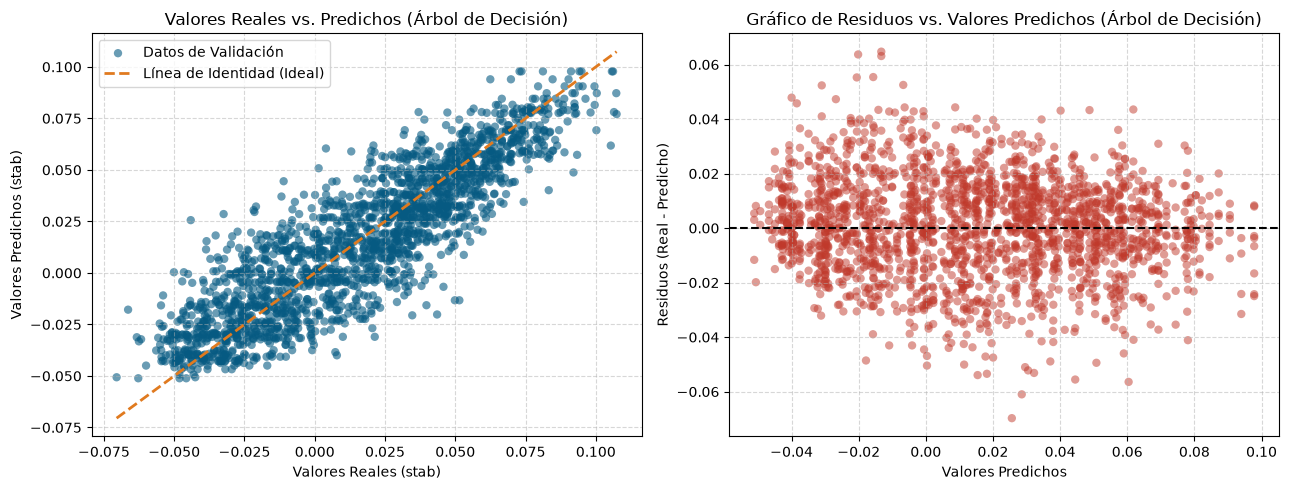

In [30]:
# Calcular los residuos para el Árbol de Decisión
residuos_tree = y_val - y_val_pred_tree

# Generar de Gráficos de Diagnóstico
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: Reales vs Predichos (Árbol de Decisión)
ax[0].scatter(y_val, y_val_pred_tree, color=AZUL, alpha=0.6, edgecolors='none', label="Datos de Validación")
max_val_tree = max(y_val.max(), y_val_pred_tree.max())
min_val_tree = min(y_val.min(), y_val_pred_tree.min())
ax[0].plot([min_val_tree, max_val_tree], [min_val_tree, max_val_tree], color=NARANJA, ls="--", lw=2, label="Línea de Identidad (Ideal)")
ax[0].set_xlabel("Valores Reales (stab)")
ax[0].set_ylabel("Valores Predichos (stab)")
ax[0].set_title("Valores Reales vs. Predichos (Árbol de Decisión)")
ax[0].legend(frameon=True)
ax[0].grid(True, linestyle="--", alpha=0.5)

# Gráfico 2: Análisis de Residuos (Homocedasticidad - Árbol de Decisión)
ax[1].scatter(y_val_pred_tree, residuos_tree, color=ROJO, alpha=0.5, edgecolors='none')
ax[1].axhline(0, color="black", ls="--", lw=1.5)
ax[1].set_xlabel("Valores Predichos")
ax[1].set_ylabel("Residuos (Real - Predicho)")
ax[1].set_title("Gráfico de Residuos vs. Valores Predichos (Árbol de Decisión)")
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 4. Comparación y Selección del Mejor Modelo
En esta sección final, consolidamos los resultados de validación cruzada y de evaluación en el conjunto de prueba independiente para determinar cuál es el modelo con el mejor compromiso entre sesgo y varianza.

### 4.1 Consolidación y Visualización de Métricas de Modelos

=== TABLA COMPARATIVA DE RENDIMIENTO EN VALIDACIÓN ===


,Modelo,RMSE Validación,R² Validación
3,SVR,0.007798,0.956533
1,Regresion_Polinomial,0.008806,0.944563
0,Regresion_Lineal,0.014005,0.859786
2,Ridge,0.014005,0.859787
4,Arbol_Decision,0.018003,0.768306




 === GRÁFICA DE BARRAS COMPARATIVA DE RENDIMIENTO EN VALIDACIÓN ===


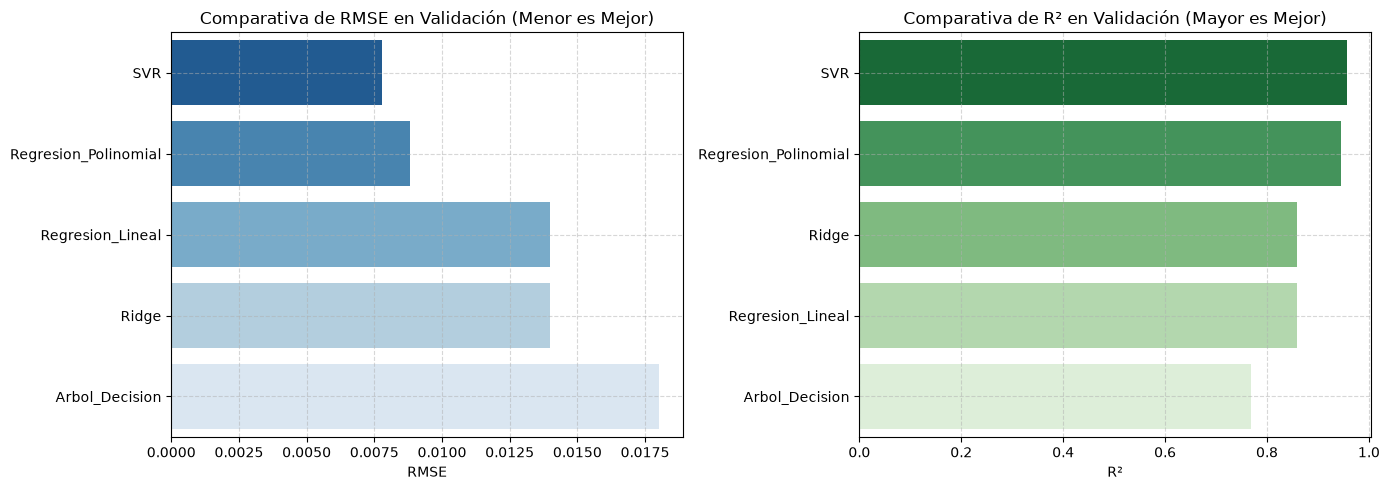

In [31]:
# Crear DataFrame a partir del diccionario de evaluación estructurado
filas_eval = []
for nombre_modelo, info in eval_modelos.items():
    metricas = info["Métricas"]
    filas_eval.append({
        "Modelo": nombre_modelo,
        "RMSE Validación": metricas.get("RMSE_val"),
        "R² Validación": metricas.get("R2_val")
    })

df_eval_final = pd.DataFrame(filas_eval).sort_values(by="RMSE Validación")

print("=== TABLA COMPARATIVA DE RENDIMIENTO EN VALIDACIÓN ===")
display(df_eval_final.round(6))

print("\n\n === GRÁFICA DE BARRAS COMPARATIVA DE RENDIMIENTO EN VALIDACIÓN ===")
# Gráfica de barras para comparar el RMSE y R² de los modelos
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Comparativa de RMSE
sns.barplot(
    x="RMSE Validación",
    y="Modelo",
    data=df_eval_final,
    ax=ax[0],
    palette="Blues_r",
    hue="Modelo",
    legend=False
)
ax[0].set_title("Comparativa de RMSE en Validación (Menor es Mejor)")
ax[0].set_xlabel("RMSE")
ax[0].set_ylabel("")
ax[0].grid(True, linestyle="--", alpha=0.5)

# Gráfico 2: Comparativa de R²
sns.barplot(
    x="R² Validación",
    y="Modelo",
    data=df_eval_final.sort_values(by="R² Validación", ascending=False),
    ax=ax[1],
    palette="Greens_r",
    hue="Modelo",
    legend=False
)
ax[1].set_title("Comparativa de R² en Validación (Mayor es Mejor)")
ax[1].set_xlabel("R²")
ax[1].set_ylabel("")
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 4.2 Comparativa de Desempeño de Folds en Validación Cruzada

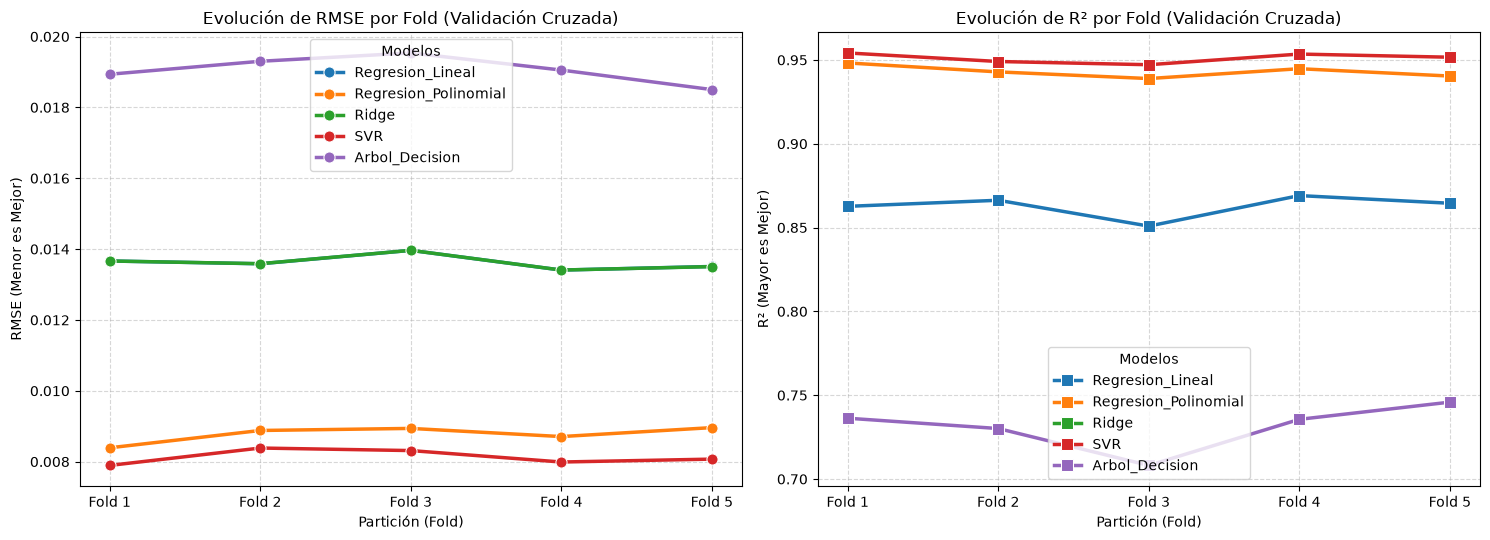

In [32]:
# Estructuramos los resultados de los folds para graficarlos
filas_folds = []
for nombre_modelo, info in resultados_modelos.items():
    folds_rmse = info.get('folds_rmse', [])
    folds_r2 = info.get('folds_r2', [])

    for num_fold in range(5):
        filas_folds.append({
            "Modelo": nombre_modelo,
            "Fold": f"Fold {num_fold + 1}",
            "RMSE": folds_rmse[num_fold] if num_fold < len(folds_rmse) else np.nan,
            "R²": folds_r2[num_fold] if num_fold < len(folds_r2) else np.nan
        })

df_folds = pd.DataFrame(filas_folds)

# Creamos las figuras
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

# Gráfico 1: RMSE por Fold
sns.lineplot(
    data=df_folds,
    x="Fold",
    y="RMSE",
    hue="Modelo",
    marker="o",
    linewidth=2.5,
    markersize=8,
    ax=ax[0]
)
ax[0].set_title("Evolución de RMSE por Fold (Validación Cruzada)", fontsize=12)
ax[0].set_xlabel("Partición (Fold)")
ax[0].set_ylabel("RMSE (Menor es Mejor)")
ax[0].grid(True, linestyle="--", alpha=0.5)
ax[0].legend(title="Modelos", frameon=True)

# Gráfico 2: R² por Fold
sns.lineplot(
    data=df_folds,
    x="Fold",
    y="R²",
    hue="Modelo",
    marker="s",
    linewidth=2.5,
    markersize=8,
    ax=ax[1]
)
ax[1].set_title("Evolución de R² por Fold (Validación Cruzada)", fontsize=12)
ax[1].set_xlabel("Partición (Fold)")
ax[1].set_ylabel("R² (Mayor es Mejor)")
ax[1].grid(True, linestyle="--", alpha=0.5)
ax[1].legend(title="Modelos", frameon=True)

plt.tight_layout()
plt.show()

### 4.3 Conclusión y Justificación del Modelo Óptimo

Con base en los resultados de validación cruzada (5-Fold CV) y en la evaluación final sobre el conjunto de validación independiente, se obtienen las siguientes conclusiones:

1. **Máximo Rendimiento (SVR con Kernel RBF):**
   * El modelo **SVR (Support Vector Regressor)** obtuvo el mejor rendimiento absoluto, alcanzando el **menor RMSE (0.007798)** y el **mayor coeficiente de determinación ($R^2$ de 95.65%)**.
   * Esto demuestra que la relación entre los parámetros de entrada de la red eléctrica y la estabilidad del sistema (`stab`) son no lineales y kernel RBF logra mapear con la mayor precisión sin requerir de una expansión polinomial de variables que infle artificialmente las dimensiones del problema.

2. **Excelente Alternativa Paramétrica (Regresión Polinomial de Grado 3):**
   * La **Regresión Polinomial de Grado 3** obtuvo un rendimiento sumamente cercano, con un **RMSE de 0.008806** y un **$R^2$ de 94.46%**.
   * Sin embargo, el modelo SVR sigue siendo el mejor debido a que la expansión de variables a grado 3 incrementa exponencialmente el número de términos en el modelo lineal, aumentando la complejidad computacional y el riesgo de sobreajuste.

3. **Modelos Lineales (Regresión Lineal y Ridge):**
   * Tanto la **Regresión Lineal Múltiple** como la **Regresión Ridge** obtuvieron métricas idénticas (**RMSE: 0.014005** | **$R^2$: 85.98%**).
   * La similitud en sus resultados indica que el pipeline de preprocesamiento construido (Lasso para selección de características y eliminación de colinealidad con `p1`) fue tan robusto que la regularización Ridge apenas tuvo que penalizar los coeficientes para mantener la estabilidad.

4. **Menor Desempeño (Árbol de Decisión):**
   * El **Árbol de Decisión** arrojó el desempeño más bajo del conjunto (**RMSE de 0.018003** y un **$R^2$ de 76.83%**).
   * Esto se debe a que las decisiones independientes de un árbol de regresión individual tienden a construir predicciones en forma de "escalones", lo que dificulta aproximar de manera suave la continuidad de la variable objetivo de estabilidad.

### **Selección Final:**
El modelo elegido es el **SVR (Support Vector Regressor)** con hiperparámetros optimizados (`C=0.1`, `epsilon=0.01`, `gamma='scale'`), ya que proporciona la mayor precisión predictiva y un excelente control de varianza.

# 5. La prueba de fuego: Evaluación final del conjunto de prueba

### 5.1 Carga archivo de pruebas

In [ ]:
archivo_prueba = 'electrical_grid_stability_test.csv'

df_test = pd.read_csv(archivo_prueba)
columnas = df_test.columns
print(f"Forma (filas: {df_test.shape[0]} · columnas: {df_test.shape[1]})")
df_test.head()


### 5.2 Evaluación del conjunto de pruebas

In [ ]:
# 1. Preparar las características del conjunto de pruebas utilizando el pipeline entrenado
# Validamos si la columna objetivo 'stab' está presente en el archivo de prueba
target_present = var_objetivo in df_test.columns

if target_present:
    print("La columna objetivo 'stab' está presente en el conjunto de pruebas. Se aislará para la evaluación.")
    X_test_raw = df_test.drop(columns=['stab'])
    y_test = df_test['stab']
else:
    print("La columna objetivo 'stab' NO está presente en el conjunto de pruebas (evaluación a ciegas).")
    X_test_raw = df_test.copy()

# Transformamos las variables de prueba a su representación final con el pipeline integrado
X_test_final_raw = feature_pipeline.transform(X_test_raw)
X_test_final = pd.DataFrame(X_test_final_raw, columns=variables_soportadas, index=X_test_raw.index)

# 2. Generar las predicciones para cada uno de los modelos finales entrenados
predicciones_test = {}

# Regresión Lineal
predicciones_test['Regresión Lineal'] = modelo_lr_final.predict(X_test_final)

# Regresión Ridge
predicciones_test['Ridge'] = modelo_ridge_final.predict(X_test_final)

# Regresión Polinomial (requiere su pipeline completo que expande internamente)
predicciones_test['Regresión Polinomial'] = pipeline_poly_final.predict(X_test_raw)

# SVR
predicciones_test['SVR (RBF)'] = modelo_svr_final.predict(X_test_final)

# Árbol de Decisión
predicciones_test['Árbol de Decisión'] = modelo_tree_final.predict(X_test_final)

# 3. Consolidar las predicciones en un DataFrame para su análisis visual comparativo
df_predicciones_test = pd.DataFrame(predicciones_test)

if target_present:
    # 4. Calcular el RMSE real para cada uno de los modelos
    print("=== EVALUACIÓN DE RENDIMIENTO (RMSE) EN EL SET DE PRUEBAS ===")
    resultados_rmse = {}
    for col in df_predicciones_test.columns:
        rmse_m = root_mean_squared_error(y_test, df_predicciones_test[col])
        resultados_rmse[col] = rmse_m
    
    df_rmse_test = pd.Series(resultados_rmse, name="RMSE de Prueba").to_frame()
    display(df_rmse_test.round(6))
    
else:
    print("=== PREDICTOR DE ESTABILIDAD: VISTA PREVIA DE LAS PREDICCIONES DEL SET DE PRUEBA ===")
    display(df_predicciones_test.head(10).round(6))

    # 4. Mostrar estadísticas descriptivas comparativas de las predicciones
    print("\n=== RESUMEN ESTADÍSTICO DE LAS PREDICCIONES ===")
    display(df_predicciones_test.describe().round(6))

In [ ]:
# Visualización de la distribución de las predicciones generadas por cada modelo en el set de pruebas

if target_present:
    # Convertimos el diccionario resultados_rmse a un DataFrame estructurado para graficar
    df_rmse_plot = pd.DataFrame(list(resultados_rmse.items()), columns=['Modelo', 'RMSE de Prueba'])
    df_rmse_plot = df_rmse_plot.sort_values(by='RMSE de Prueba')

    # Configuración de la figura
    plt.figure(figsize=(10, 5))
    sns.barplot(
        x='RMSE de Prueba',
        y='Modelo',
        data=df_rmse_plot,
        palette='Blues_r',
        hue='Modelo',
        legend=False
    )

    # Añadimos etiquetas con el valor exacto en cada barra para una lectura precisa
    for index, row in enumerate(df_rmse_plot.itertuples()):
        val_rmse = getattr(row, '_2')
        plt.text(
            val_rmse + 0.0001,
            index,
            f'{val_rmse:.6f}',
            va='center',
            fontsize=10,
            color='black'
        )

    plt.title("Comparativa de RMSE en el Set de Prueba (Menor es Mejor)", fontsize=12, fontweight='bold')
    plt.xlabel("Root Mean Squared Error (RMSE)")
    plt.ylabel("Modelo")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.xlim(0, df_rmse_plot['RMSE de Prueba'].max() * 1.2)
    plt.tight_layout()
    plt.show()
else:
    print("=== DISTRIBUCIÓN DE LAS PREDICCIONES EN EL SET DE PRUEBAS ===")
    plt.figure(figsize=(10, 6))
    for col in df_predicciones_test.columns:
        sns.kdeplot(df_predicciones_test[col], label=col, fill=True, alpha=0.15)

    plt.title("Distribución de Estabilidad ('stab') Predicha según cada Modelo en el Set de Prueba", fontsize=12)
    plt.xlabel("Valor de Estabilidad Predicho (stab)")
    plt.ylabel("Densidad de Probabilidad")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(title="Modelos")
    plt.show()
    
